<a href="https://colab.research.google.com/github/ahmed-id-machiche/deep_learning_tps/blob/main/TP4_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [18]:
# 1 Load the IMDb dataset (top 10,000 most frequent words)
num_words = 10000
maxlen = 256
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)

In [19]:
# 2 Inspect dataset sample counts
print(f"Training samples: {len(x_train)} | Test samples: {len(x_test)}")

Training samples: 25000 | Test samples: 25000


In [20]:
# 3 Pad sequences to uniform length (256 words per review)
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

In [21]:
# 4. Check shapes of x_train and y_train
print(f"x_train shape: {x_train.shape}")  # Output: (25000, 256)
print(f"y_train shape: {y_train.shape}")  # Output: (25000,)

x_train shape: (25000, 256)
y_train shape: (25000,)


In [23]:
# Non-Regularized Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

def build_base_model():
    model = Sequential([
        Embedding(input_dim=10000, output_dim=32, input_length=256),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model
base_model = build_base_model()
history_base = base_model.fit(
    x_train, y_train,
    epochs=12,
    batch_size=512,
    validation_split=0.2
)
test_loss_base, test_acc_base = base_model.evaluate(x_test, y_test, verbose=0)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.6074 - loss: 0.6500 - val_accuracy: 0.7690 - val_loss: 0.4784
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - accuracy: 0.8672 - loss: 0.3094 - val_accuracy: 0.8560 - val_loss: 0.3320
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.9606 - loss: 0.1207 - val_accuracy: 0.8632 - val_loss: 0.3461
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.9922 - loss: 0.0349 - val_accuracy: 0.8530 - val_loss: 0.4402
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.9988 - loss: 0.0090 - val_accuracy: 0.8564 - val_loss: 0.4984
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.9998 - loss: 0.0029 - val_accuracy: 0.8528 - val_loss: 0.5481
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.8542 - val_loss: 0.5744
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 1.0000 - loss: 6.3847e-04 - val_accuracy: 0.

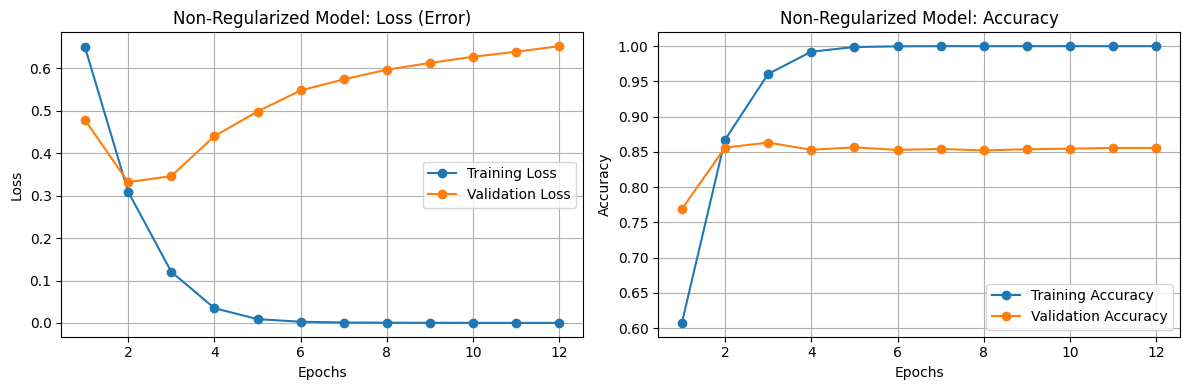

Test Loss: 0.6511 - Test Accuracy: 0.8530


In [24]:
import matplotlib.pyplot as plt

# Extract metrics from history_base
epochs = range(1, len(history_base.history['loss']) + 1)
train_loss = history_base.history['loss']
val_loss = history_base.history['val_loss']
train_acc = history_base.history['accuracy']
val_acc = history_base.history['val_accuracy']

# Create side-by-side plots for Loss and Accuracy
plt.figure(figsize=(12, 4))

# 1. Training vs. Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Training Loss', marker='o')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
plt.title('Non-Regularized Model: Loss (Error)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 2. Training vs. Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, label='Training Accuracy', marker='o')
plt.plot(epochs, val_acc, label='Validation Accuracy', marker='o')
plt.title('Non-Regularized Model: Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print final test evaluation results
print(f"Test Loss: {test_loss_base:.4f} - Test Accuracy: {test_acc_base:.4f}")

In [26]:
import matplotlib.pyplot as plt

def plot_model_results(history, model_name, test_loss, test_acc):
    epochs = range(1, len(history.history['loss']) + 1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    plt.figure(figsize=(12, 4))

    # 1. Training vs. Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label='Training Loss', marker='o')
    plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
    plt.title(f'{model_name}: Loss (Error)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # 2. Training vs. Validation Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label='Training Accuracy', marker='o')
    plt.plot(epochs, val_acc, label='Validation Accuracy', marker='o')
    plt.title(f'{model_name}: Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    print(f"[{model_name}] Stopped at Epoch: {len(epochs)} | Test Loss: {test_loss:.4f} - Test Accuracy: {test_acc:.4f}\n")

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 134ms/step - accuracy: 0.6072 - loss: 0.8012 - val_accuracy: 0.7928 - val_loss: 0.5357
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.8666 - loss: 0.4011 - val_accuracy: 0.8582 - val_loss: 0.4070
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 119ms/step - accuracy: 0.9436 - loss: 0.2526 - val_accuracy: 0.8690 - val_loss: 0.3984
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.9828 - loss: 0.1602 - val_accuracy: 0.8432 - val_loss: 0.4673
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 0.9955 - loss: 0.1142 - val_accuracy: 0.8644 - val_loss: 0.4261
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 117ms/step - accuracy: 0.9986 - loss: 0.0874 - val_accuracy: 0.8528 - val_loss: 0.4665
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9989 - loss: 0.0782 - val_accuracy: 0.8610 - val_loss: 0.4345
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.9998 - loss: 0.0659 - val_accuracy: 0.

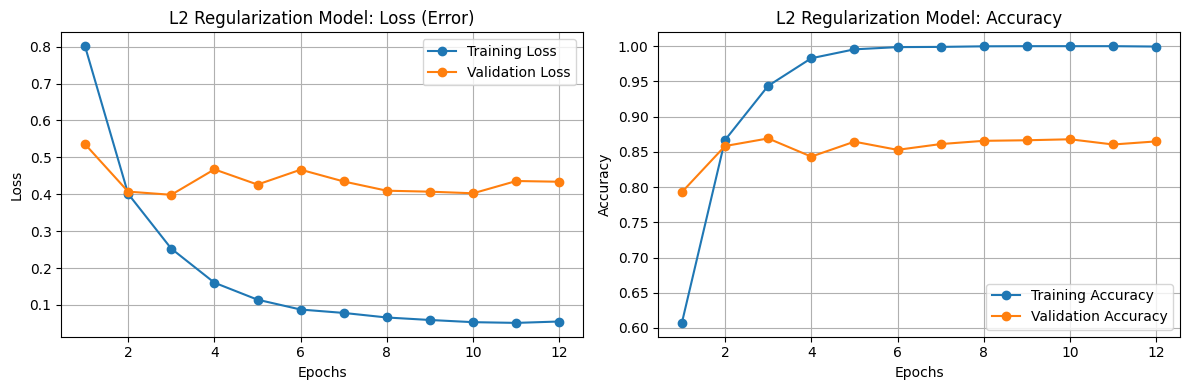

[L2 Regularization Model] Stopped at Epoch: 12 | Test Loss: 0.4415 - Test Accuracy: 0.8597



In [27]:
# --- 5. L2 Regularization ---
from tensorflow.keras import regularizers

model_l2 = Sequential([
    Embedding(input_dim=10000, output_dim=32, input_length=256),
    Flatten(),
    Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    Dense(1, activation='sigmoid')
])
model_l2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history_l2 = model_l2.fit(x_train, y_train, epochs=12, batch_size=512, validation_split=0.2)
test_loss_l2, test_acc_l2 = model_l2.evaluate(x_test, y_test, verbose=0)

plot_model_results(history_l2, "L2 Regularization Model", test_loss_l2, test_acc_l2)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 120ms/step - accuracy: 0.5361 - loss: 0.6901 - val_accuracy: 0.7006 - val_loss: 0.6613
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.7819 - loss: 0.4877 - val_accuracy: 0.8538 - val_loss: 0.3386
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9103 - loss: 0.2385 - val_accuracy: 0.8708 - val_loss: 0.3208
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.9654 - loss: 0.1081 - val_accuracy: 0.8532 - val_loss: 0.4102
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.9863 - loss: 0.0454 - val_accuracy: 0.8504 - val_loss: 0.5178
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.9958 - loss: 0.0174 - val_accuracy: 0.8584 - val_loss: 0.5651
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.9987 - loss: 0.0075 - val_accuracy: 0.8600 - val_loss: 0.6088
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.9996 - loss: 0.0039 - val_accuracy: 0.8588

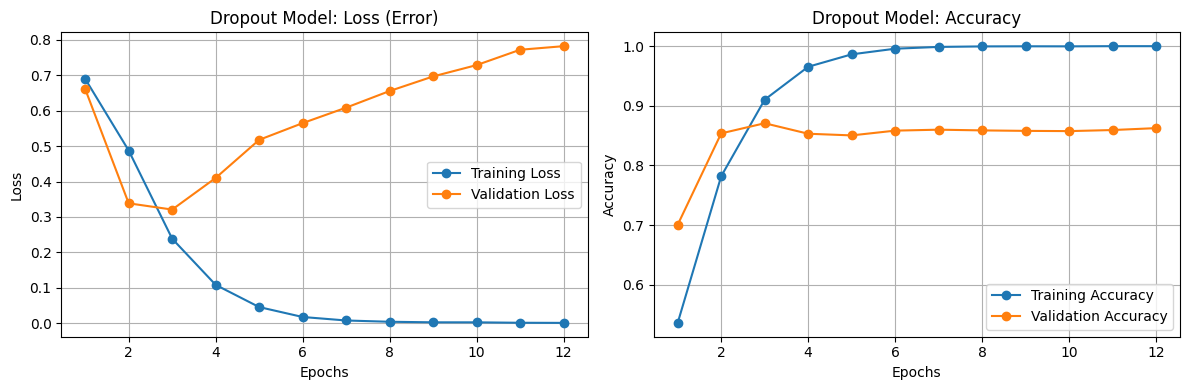

[Dropout Model] Stopped at Epoch: 12 | Test Loss: 0.8175 - Test Accuracy: 0.8554



In [28]:
# Dropout
from tensorflow.keras.layers import Dropout

model_dropout = Sequential([
    Embedding(input_dim=10000, output_dim=32, input_length=256),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])
model_dropout.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history_dropout = model_dropout.fit(x_train, y_train, epochs=12, batch_size=512, validation_split=0.2)
test_loss_drop, test_acc_drop = model_dropout.evaluate(x_test, y_test, verbose=0)

plot_model_results(history_dropout, "Dropout Model", test_loss_drop, test_acc_drop)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 0.5734 - loss: 0.6753 - val_accuracy: 0.7398 - val_loss: 0.5376
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.8525 - loss: 0.3417 - val_accuracy: 0.8516 - val_loss: 0.3306
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.9563 - loss: 0.1271 - val_accuracy: 0.8536 - val_loss: 0.3789
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.9918 - loss: 0.0355 - val_accuracy: 0.8570 - val_loss: 0.4370
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.9985 - loss: 0.0101 - val_accuracy: 0.8526 - val_loss: 0.5133


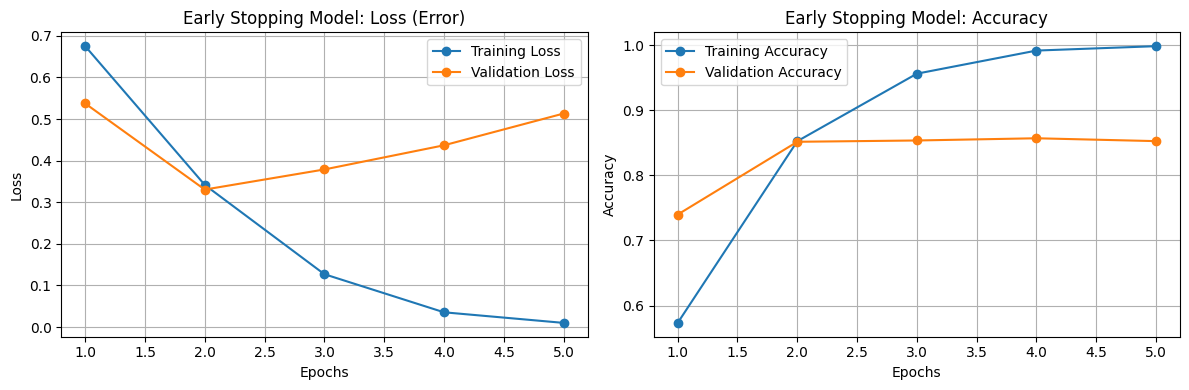

[Early Stopping Model] Stopped at Epoch: 5 | Test Loss: 0.3326 - Test Accuracy: 0.8554



In [29]:
# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

model_es = build_base_model()
history_es = model_es.fit(
    x_train, y_train,
    epochs=15,
    batch_size=512,
    validation_split=0.2,
    callbacks=[early_stopping]
)
test_loss_es, test_acc_es = model_es.evaluate(x_test, y_test, verbose=0)

plot_model_results(history_es, "Early Stopping Model", test_loss_es, test_acc_es)

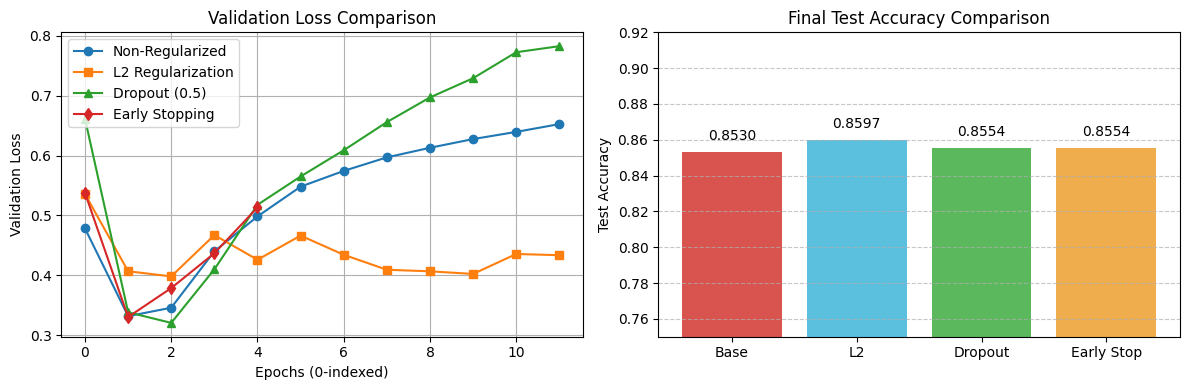

In [30]:
plt.figure(figsize=(12, 4))

# 1. Compare Validation Loss Curves Across Models
plt.subplot(1, 2, 1)
plt.plot(history_base.history['val_loss'], label='Non-Regularized', marker='o')
plt.plot(history_l2.history['val_loss'], label='L2 Regularization', marker='s')
plt.plot(history_dropout.history['val_loss'], label='Dropout (0.5)', marker='^')
plt.plot(history_es.history['val_loss'], label='Early Stopping', marker='d')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs (0-indexed)')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)

# 2. Compare Final Test Accuracy (Bar Chart)
plt.subplot(1, 2, 2)
model_names = ['Base', 'L2', 'Dropout', 'Early Stop']
test_accuracies = [test_acc_base, test_acc_l2, test_acc_drop, test_acc_es]
bars = plt.bar(model_names, test_accuracies, color=['#d9534f', '#5bc0de', '#5cb85c', '#f0ad4e'])
plt.title('Final Test Accuracy Comparison')
plt.ylabel('Test Accuracy')
plt.ylim(0.75, 0.92)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
from IPython.display import display

# Best epoch index for Early Stopping (where validation loss was lowest)
best_es_idx = history_es.history['val_loss'].index(min(history_es.history['val_loss']))

# Build numerical-only table data
numeric_data = [
    {
        "Model / Technique": "<b>Non-Regularized</b>",
        "Train Loss": f"{history_base.history['loss'][-1]:.4f}",
        "Val Loss": f"{history_base.history['val_loss'][-1]:.4f}",
        "Test Loss": f"{test_loss_base:.4f}",
        "Test Acc": f"{test_acc_base * 100:.2f}%"
    },
    {
        "Model / Technique": "<b>L2 Regularization</b> (0.001)",
        "Train Loss": f"{history_l2.history['loss'][-1]:.4f}",
        "Val Loss": f"{history_l2.history['val_loss'][-1]:.4f}",
        "Test Loss": f"{test_loss_l2:.4f}",
        "Test Acc": f"{test_acc_l2 * 100:.2f}%"
    },
    {
        "Model / Technique": "<b>Dropout</b> (0.5)",
        "Train Loss": f"{history_dropout.history['loss'][-1]:.4f}",
        "Val Loss": f"{history_dropout.history['val_loss'][-1]:.4f}",
        "Test Loss": f"{test_loss_drop:.4f}",
        "Test Acc": f"{test_acc_drop * 100:.2f}%"
    },
    {
        "Model / Technique": "<b>Early Stopping</b> (3)",
        "Train Loss": f"{history_es.history['loss'][best_es_idx]:.4f}",
        "Val Loss": f"{history_es.history['val_loss'][best_es_idx]:.4f}",
        "Test Loss": f"{test_loss_es:.4f}",
        "Test Acc": f"{test_acc_es * 100:.2f}%"
    }
]

df_numbers = pd.DataFrame(numeric_data)

# Apply the clean light-mode royal blue & white table styling
styled_numbers_table = (
    df_numbers.style
    .hide(axis='index')
    .set_table_styles([
        {'selector': 'table', 'props': [
            ('border-collapse', 'collapse'),
            ('width', '100%'),
            ('font-family', '"Segoe UI", Roboto, Arial, sans-serif')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#1d3a8a'),
            ('color', '#ffffff'),
            ('font-weight', '600'),
            ('text-align', 'center'),
            ('padding', '12px 16px'),
            ('border', '1px solid #cbd5e1'),
            ('font-size', '14px')
        ]},
        {'selector': 'th:first-child', 'props': [('text-align', 'left')]},
        {'selector': 'td', 'props': [
            ('text-align', 'center'),
            ('padding', '12px 16px'),
            ('color', '#1e293b'),
            ('border', '1px solid #cbd5e1'),
            ('font-size', '14px')
        ]},
        {'selector': 'td:first-child', 'props': [('text-align', 'left')]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [('background-color', '#ffffff')]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [('background-color', '#f8fafc')]}
    ])
)

display(styled_numbers_table)

Model / Technique,Train Loss,Val Loss,Test Loss,Test Acc
Non-Regularized,0.0002,0.6525,0.6511,85.30%
L2 Regularization (0.001),0.0550,0.4338,0.4415,85.97%
Dropout (0.5),0.0007,0.7825,0.8175,85.54%
Early Stopping (3),0.3417,0.3306,0.3326,85.54%
